
# Fraud Detection System

## Project Overview

Credit card fraud is a significant challenge in financial transactions. Identifying potentially fraudulent transactions is important for reducing financial losses and improving transaction security.

This project explores the development of a machine learning-based fraud detection system using the Credit Card Fraud Detection dataset provided by the Machine Learning Group of ULB.

The project involves exploratory data analysis, data preprocessing, handling class imbalance, model development, evaluation, and threshold optimisation.

The final system uses a Random Forest model trained with SMOTE to estimate the likelihood of a transaction being fraudulent.

The intended application follows a human-in-the-loop approach: the model provides a fraud risk assessment, while the human reviewer retains responsibility for the final decision.

## Project Objectives

- Understand the structure and characteristics of the dataset.
- Explore the distribution of legitimate and fraudulent transactions.
- Investigate the challenges associated with class imbalance.
- Develop and compare machine learning models.
- Evaluate model performance using appropriate classification metrics.
- Select and optimise a suitable model.
- Save the final model for integration into an application.


In [68]:
import os
import warnings
import joblib
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

In [69]:
# Define project directory
PROJECT_DIR = Path.cwd()

# If notebook is running from notebooks/, move one level up
if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_PATH = PROJECT_DIR / "data" / "creditcard.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")

print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [70]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [71]:
# Check number of rows and columns

print("Number of rows:", df.shape[0])

print("Number of columns:", df.shape[1])

Number of rows: 284807
Number of columns: 31


In [72]:
# Check missing values

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

display(missing_values[missing_values > 0])

Total missing values: 0


Series([], dtype: int64)

In [73]:
# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

print(
    "Percentage of duplicate rows:",
    round((duplicate_count / len(df)) * 100, 4),
    "%"
)

Number of duplicate rows: 1081
Percentage of duplicate rows: 0.3796 %


In [74]:
# Statistical summary

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [75]:
# Count each class

class_counts = df["Class"].value_counts()
print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


In [76]:
# Class percentages

class_percentages = (
    df["Class"].value_counts(normalize=True) * 100
)

print(class_percentages)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [77]:
# Combine counts and percentages

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

display(class_distribution)

,Count,Percentage
Class,,
0,284315,99.827251
1,492,0.172749



### Class Distribution Findings

The dataset contains 284,315 legitimate transactions and 492 fraudulent transactions.

Fraudulent transactions represent approximately 0.173% of the dataset, while legitimate transactions account for approximately 99.827%.

This demonstrates a severe class imbalance. Consequently, accuracy alone may not provide a reliable measure of model performance.

Techniques for handling class imbalance will therefore be investigated during model development.


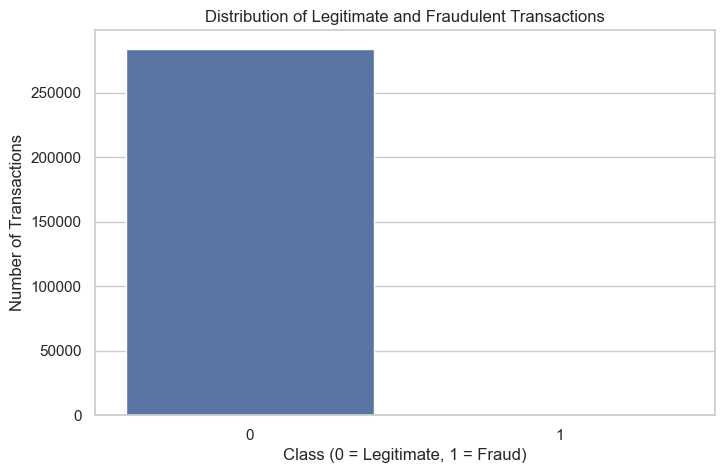

In [78]:
# Class imbalance visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribution of Legitimate and Fraudulent Transactions")

plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")

plt.ylabel("Number of Transactions")

plt.show()

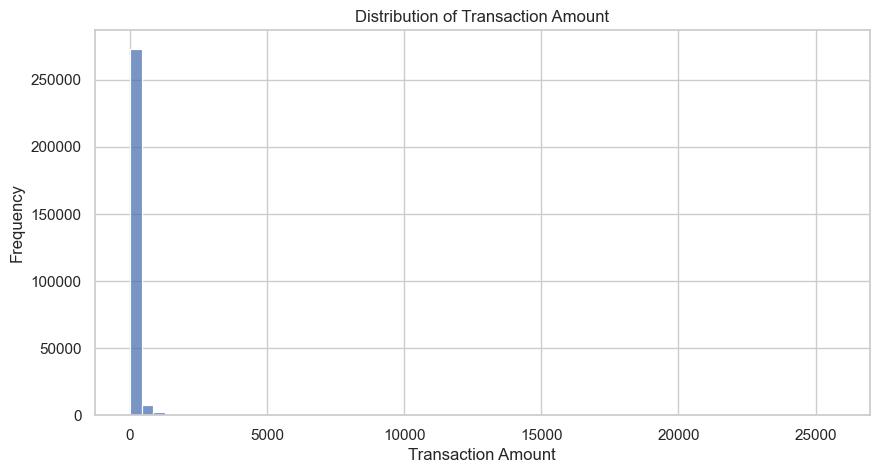

In [79]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    bins=60
)

plt.title("Distribution of Transaction Amount")

plt.xlabel("Transaction Amount")

plt.ylabel("Frequency")

plt.show()


## 4. Transaction Amount Analysis

Transaction amounts are examined to understand their distribution and investigate whether spending patterns differ between legitimate and fraudulent transactions.

Histograms and boxplots are used to compare transaction amounts across the two classes.


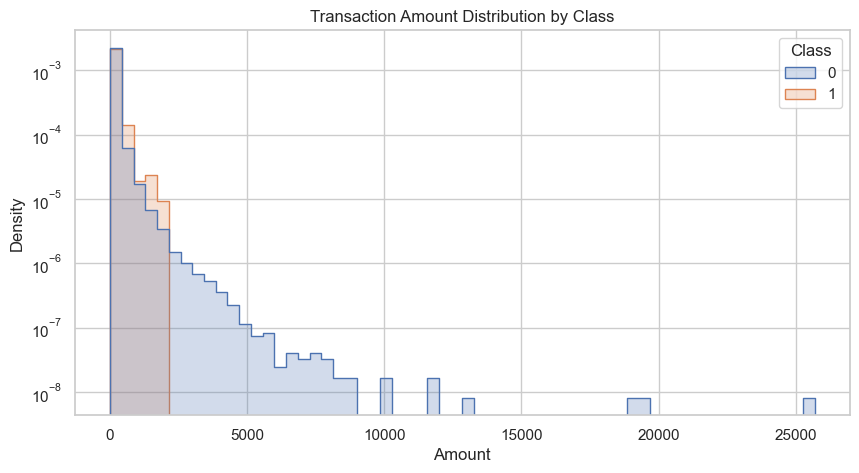

In [80]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.yscale("log")

plt.title("Transaction Amount Distribution by Class")

plt.show()

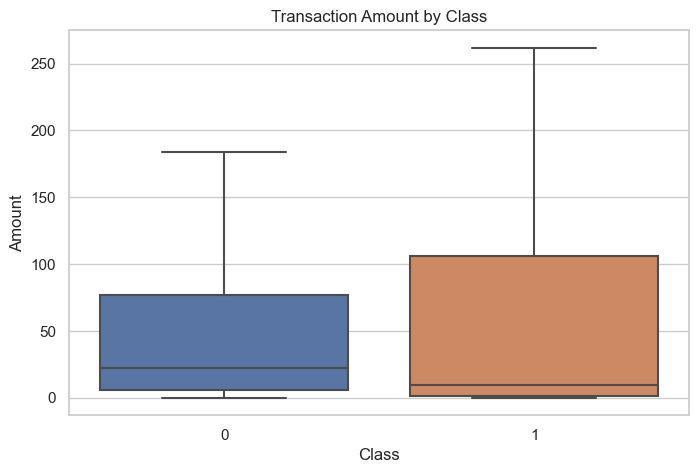

In [81]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    showfliers=False
)

plt.title("Transaction Amount by Class")

plt.xlabel("Class")

plt.ylabel("Amount")

plt.show()

In [82]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


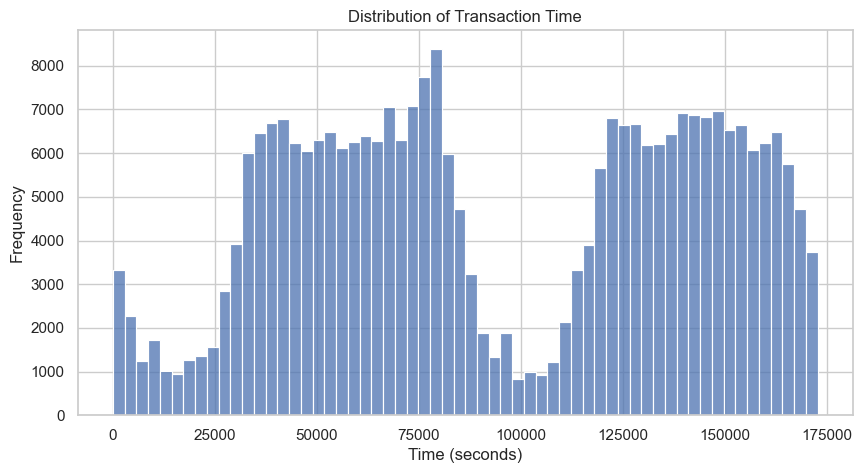

In [83]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    bins=60
)

plt.title("Distribution of Transaction Time")

plt.xlabel("Time (seconds)")

plt.ylabel("Frequency")

plt.show()


### Transaction Amount Findings

The analysis shows differences in the distribution of transaction amounts between legitimate and fraudulent transactions.

However, the distributions overlap, indicating that transaction amount alone is insufficient to distinguish fraudulent transactions reliably.


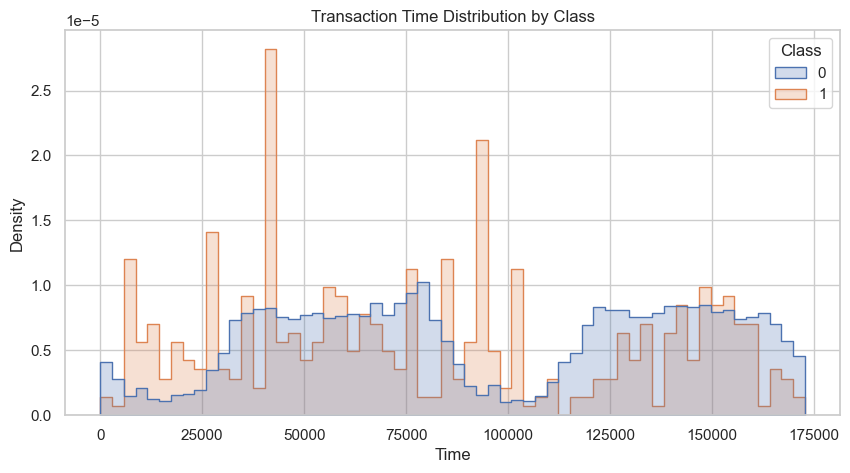

In [84]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=60,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Transaction Time Distribution by Class")

plt.show()


## 5. Transaction Time Analysis

The Time feature represents the elapsed time in seconds between each transaction and the first transaction recorded in the dataset.

Its distribution is examined to investigate whether fraudulent transactions exhibit different temporal patterns from legitimate transactions.


In [85]:
df.groupby("Class")["Time"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,94838.202258,47484.015786,0.0,54230.0,84711.0,139333.0,172792.0
1,492.0,80746.806911,47835.365138,406.0,41241.5,75568.5,128483.0,170348.0


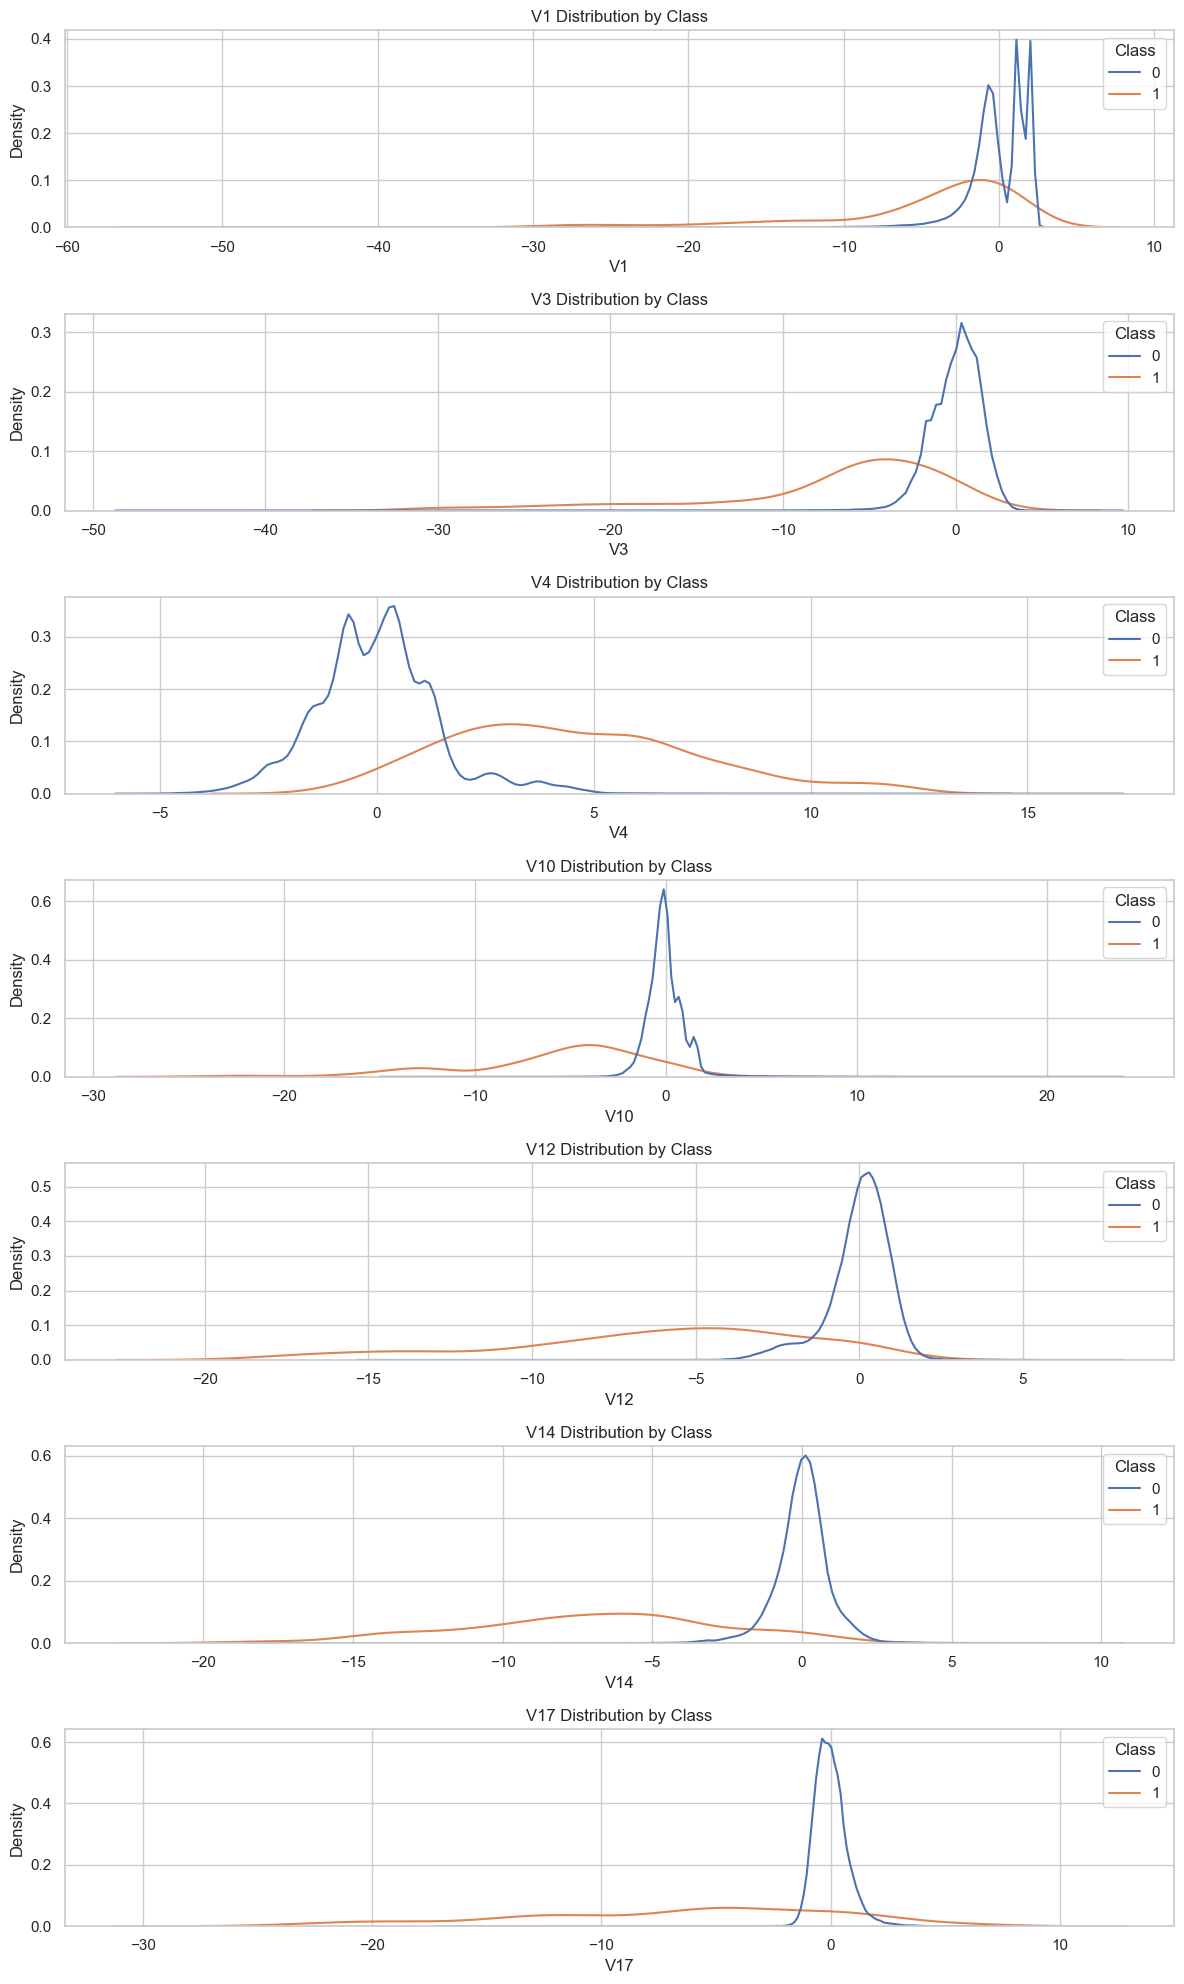

In [86]:
selected_features = [
    "V1",
    "V3",
    "V4",
    "V10",
    "V12",
    "V14",
    "V17"
]

fig, axes = plt.subplots(
    len(selected_features),
    1,
    figsize=(12, 20)
)

for feature, ax in zip(selected_features, axes):

    sns.kdeplot(
        data=df,
        x=feature,
        hue="Class",
        common_norm=False,
        ax=ax
    )

    ax.set_title(f"{feature} Distribution by Class")

plt.tight_layout()

plt.show()


## 7. Correlation Analysis

Correlation analysis is performed to investigate the relationships between the numerical features and the target variable.

A correlation heatmap is used to visualise these relationships, while the strongest correlations with the target variable are examined separately.


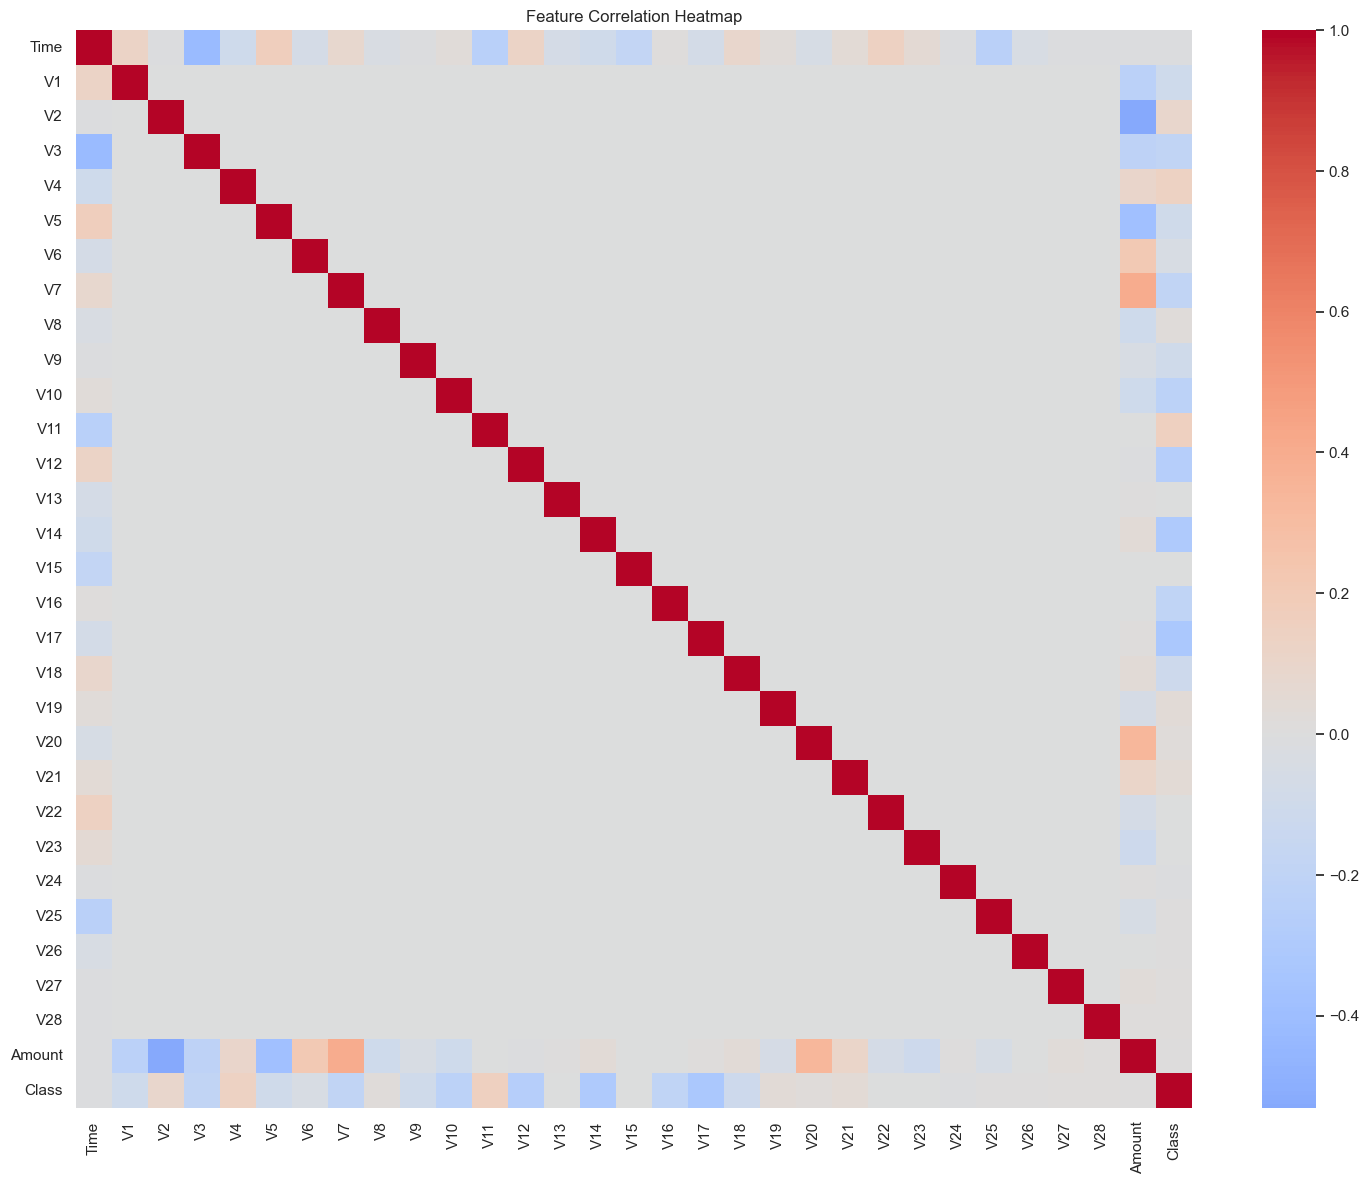

In [87]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [88]:
# Features with strongest absolute correlation with Class

correlation_matrix["Class"].drop(
    "Class"
).sort_values(
    key=lambda values: values.abs(),
    ascending=False
)

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64

### Exploratory Data Analysis Findings

- The dataset contains 284,807 transactions and 31 columns.
- The target is highly imbalanced.
- Fraud represents approximately 0.173% of the original dataset.
- Amount and Time distributions overlap between legitimate and fraudulent transactions.
- V1–V28 are anonymised PCA features.
- Accuracy alone will not be sufficient for evaluating the models.

DATA PREPROCESSING AND CLASS IMBALANCE

In [89]:
# Defining input features

feature_columns = (
    ["Time"]
    + [f"V{i}" for i in range(1, 29)]
    + ["Amount"]
)

X = df[feature_columns].copy()

# Define target

y = df["Class"].copy()

print("Feature shape:", X.shape)

print("Target shape:", y.shape)

Feature shape: (284807, 30)
Target shape: (284807,)


In [90]:
from sklearn.model_selection import train_test_split

# First split: 80% development data, 20% test data

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: training and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.20,
    random_state=42,
    stratify=y_train_val
)

In [91]:
print("Training set:", X_train.shape)

print("Validation set:", X_val.shape)

print("Test set:", X_test.shape)

Training set: (182276, 30)
Validation set: (45569, 30)
Test set: (56962, 30)


In [92]:
# Class distribution in each split

print("TRAINING DISTRIBUTION")

print(y_train.value_counts())

print("\nVALIDATION DISTRIBUTION")

print(y_val.value_counts())

print("\nTEST DISTRIBUTION")

print(y_test.value_counts())

TRAINING DISTRIBUTION
Class
0    181961
1       315
Name: count, dtype: int64

VALIDATION DISTRIBUTION
Class
0    45490
1       79
Name: count, dtype: int64

TEST DISTRIBUTION
Class
0    56864
1       98
Name: count, dtype: int64


In [93]:
# Fraud percentage in each split

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:

    print(
        name,
        "fraud percentage:",
        round(target.mean() * 100, 4),
        "%"
    )

Training fraud percentage: 0.1728 %
Validation fraud percentage: 0.1734 %
Test fraud percentage: 0.172 %


In [94]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

time_amount_scaler = ColumnTransformer(
    transformers=[
        (
            "scale_time_amount",
            StandardScaler(),
            ["Time", "Amount"]
        )
    ],
    remainder="passthrough"
)

baseline: class-weighted Logistic Regression

In [95]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

class_weight_model = Pipeline(
    steps=[
        ("preprocessor", time_amount_scaler),

        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

class_weight_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scale_time_amount', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatw

In [96]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

undersampling_model = ImbPipeline(
    steps=[
        ("scaler", StandardScaler()),

        (
            "sampler",
            RandomUnderSampler(
                sampling_strategy=0.1,
                random_state=42
            )
        ),

        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

undersampling_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [97]:
from imblearn.over_sampling import SMOTE

smote_model = ImbPipeline(
    steps=[
        ("scaler", StandardScaler()),

        (
            "sampler",
            SMOTE(
                sampling_strategy=0.1,
                random_state=42,
                k_neighbors=5
            )
        ),

        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

smote_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('sampler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](30,)","['Time','V1','V2',...,'V27','V28','Amount']"
n_features_in_,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [98]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


def evaluate_model(model, X_eval, y_eval, threshold=0.5):

    # Get fraud scores
    probabilities = model.predict_proba(X_eval)[:, 1]

    # Convert scores into predictions
    predictions = (
        probabilities >= threshold
    ).astype(int)

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        "Threshold": threshold,

        "Precision": precision_score(
            y_eval,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_eval,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_eval,
            predictions,
            zero_division=0
        ),

        "ROC_AUC": roc_auc_score(
            y_eval,
            probabilities
        ),

        "PR_AUC": average_precision_score(
            y_eval,
            probabilities
        ),

        "False Positives": fp,

        "False Negatives": fn,

        "True Positives": tp,

        "True Negatives": tn
    }

In [99]:
# Baseline Model Development

imbalance_models = {
    "Class Weighting": class_weight_model,
    "Random Undersampling": undersampling_model,
    "SMOTE": smote_model
}

imbalance_results = []

for name, model in imbalance_models.items():

    results = evaluate_model(
        model,
        X_val,
        y_val,
        threshold=0.5
    )

    results["Model"] = name

    imbalance_results.append(results)


imbalance_comparison = pd.DataFrame(
    imbalance_results
)

imbalance_comparison = imbalance_comparison.set_index(
    "Model"
)

display(imbalance_comparison.round(4))

,Threshold,Precision,Recall,F1,ROC_AUC,PR_AUC,False Positives,False Negatives,True Positives,True Negatives
Model,,,,,,,,,,
Class Weighting,0.5,0.0596,0.8861,0.1117,0.9736,0.6788,1104,9,70,44386
Random Undersampling,0.5,0.3052,0.8228,0.4452,0.9720,0.6277,148,14,65,45342
SMOTE,0.5,0.3125,0.8228,0.4530,0.9677,0.6960,143,14,65,45347



## Logistic Regression with Class Weighting

Logistic Regression is initially investigated as a baseline classification model.

Class weighting is used to assign greater importance to the minority fraud class during training.

This provides an initial approach to handling the imbalance without generating synthetic observations.


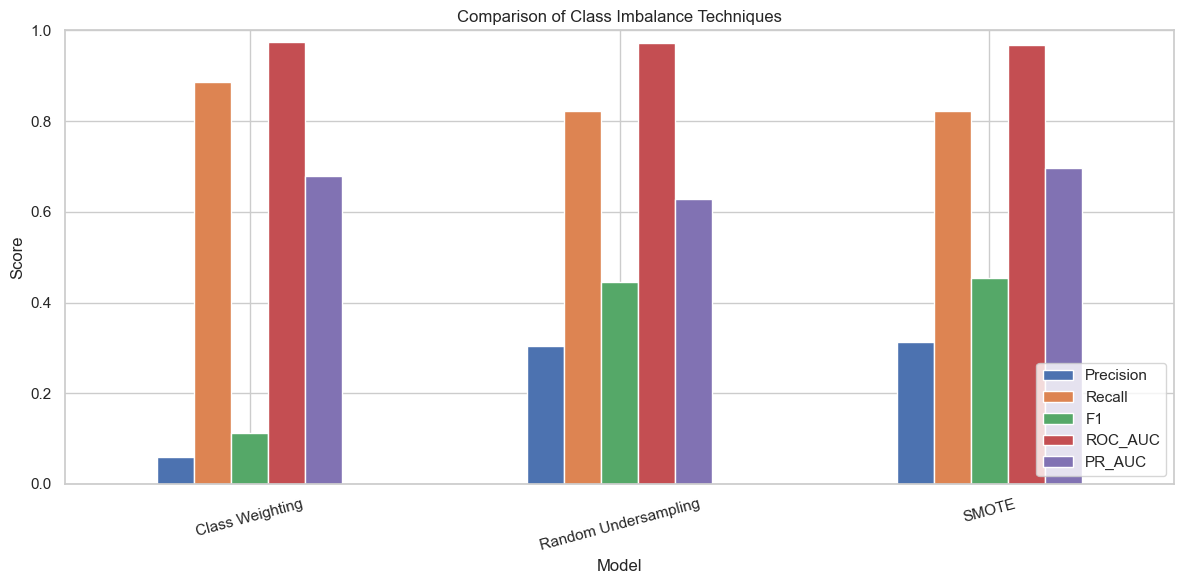

In [100]:
metrics = [
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

imbalance_comparison[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1)
)

plt.title("Comparison of Class Imbalance Techniques")

plt.ylabel("Score")

plt.xticks(rotation=15)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()


## Logistic Regression with Random Undersampling

Random undersampling is investigated as another approach to handling class imbalance.

This technique reduces the number of majority-class observations during training to create a more balanced training distribution.


In [101]:
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.utils.class_weight import compute_sample_weight


## Logistic Regression with SMOTE

Synthetic Minority Over-sampling Technique (SMOTE) is applied to increase the representation of the minority fraud class.

Rather than simply duplicating existing fraud observations, SMOTE generates synthetic minority-class samples.

The technique is applied within the training pipeline to prevent synthetic observations from entering the validation or test sets.


In [102]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", time_amount_scaler),

        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [103]:
random_forest_model = RandomForestClassifier(
    n_estimators=300,

    class_weight="balanced_subsample",

    min_samples_leaf=2,

    random_state=42,

    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [104]:
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,

    learning_rate=0.05,

    max_depth=3,

    min_samples_leaf=20,

    random_state=42
)

# Generate balanced sample weights
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Train model
gradient_boosting_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("Gradient Boosting training completed.")

Gradient Boosting training completed.


In [105]:
models = {
    "Logistic Regression": logistic_model,

    "Random Forest": random_forest_model,

    "Gradient Boosting": gradient_boosting_model
}

model_results = []

for name, model in models.items():

    results = evaluate_model(
        model,
        X_val,
        y_val,
        threshold=0.5
    )

    results["Model"] = name

    model_results.append(results)


model_comparison = pd.DataFrame(
    model_results
)

model_comparison = model_comparison.set_index(
    "Model"
)

display(model_comparison.round(4))

,Threshold,Precision,Recall,F1,ROC_AUC,PR_AUC,False Positives,False Negatives,True Positives,True Negatives
Model,,,,,,,,,,
Logistic Regression,0.5,0.0596,0.8861,0.1117,0.9736,0.6788,1104,9,70,44386
Random Forest,0.5,0.9206,0.7342,0.8169,0.9452,0.8138,5,21,58,45485
Gradient Boosting,0.5,0.1124,0.8481,0.1985,0.9786,0.7244,529,12,67,44961



# Machine Learning Model Comparison

Following the initial imbalance-handling experiments, additional classification models are investigated.

The models considered are:

- Logistic Regression
- Random Forest
- Gradient Boosting

Their performance is compared using precision, recall, F1-score, ROC-AUC and PR-AUC.

Particular attention is given to fraud detection performance because of the severe class imbalance.


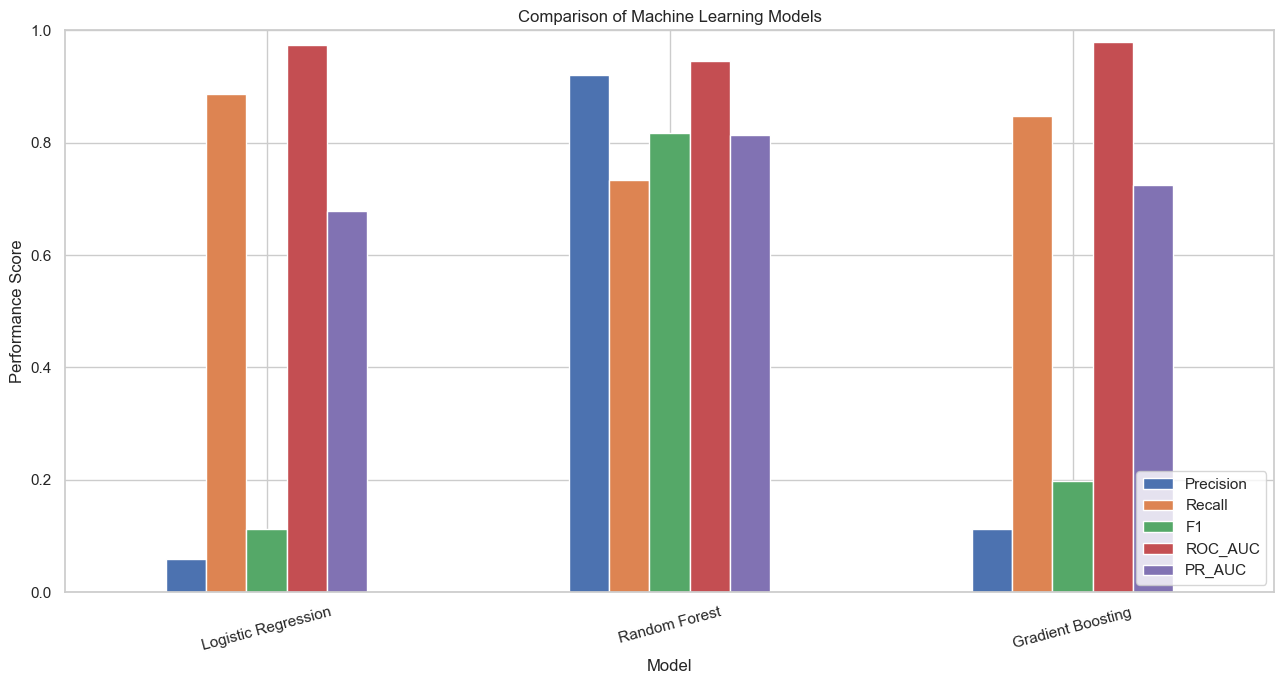

In [106]:
comparison_metrics = [
    "Precision",
    "Recall",
    "F1",
    "ROC_AUC",
    "PR_AUC"
]

model_comparison[comparison_metrics].plot(
    kind="bar",
    figsize=(13, 7),
    ylim=(0, 1)
)

plt.title("Comparison of Machine Learning Models")

plt.ylabel("Performance Score")

plt.xticks(rotation=15)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

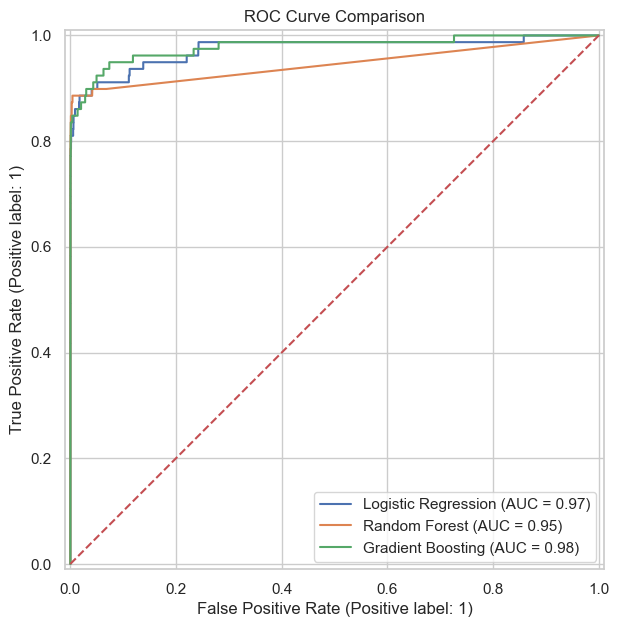

In [107]:
from sklearn.metrics import RocCurveDisplay

plt.figure(figsize=(9, 7))

for name, model in models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_val,
        y_val,
        name=name,
        ax=plt.gca()
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")

plt.show()

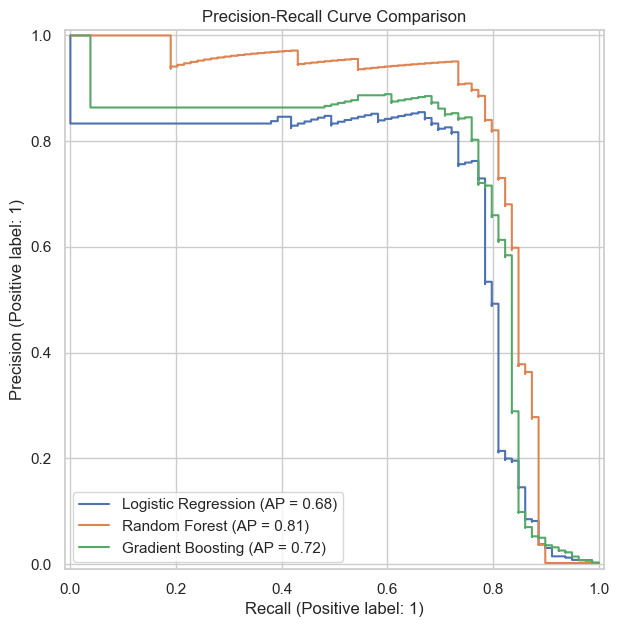

In [108]:
from sklearn.metrics import PrecisionRecallDisplay

plt.figure(figsize=(9, 7))

for name, model in models.items():

    PrecisionRecallDisplay.from_estimator(
        model,
        X_val,
        y_val,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curve Comparison")

plt.show()

In [109]:
def plot_confusion_matrix(model, X_eval, y_eval, model_name):

    predictions = model.predict(X_eval)

    cm = confusion_matrix(
        y_eval,
        predictions
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"]
    )

    plt.title(f"{model_name} Confusion Matrix")

    plt.xlabel("Predicted")

    plt.ylabel("Actual")

    plt.show()

Logistic Regression


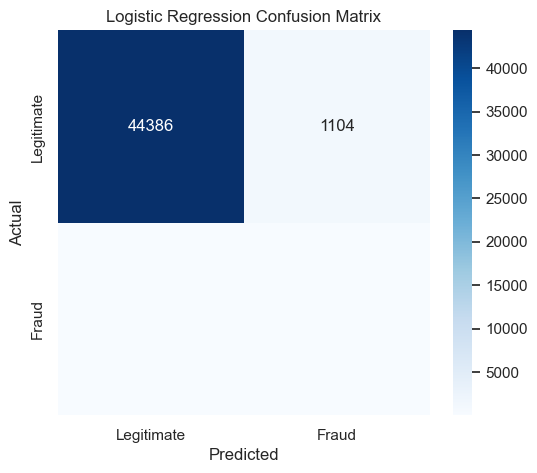

Random Forest


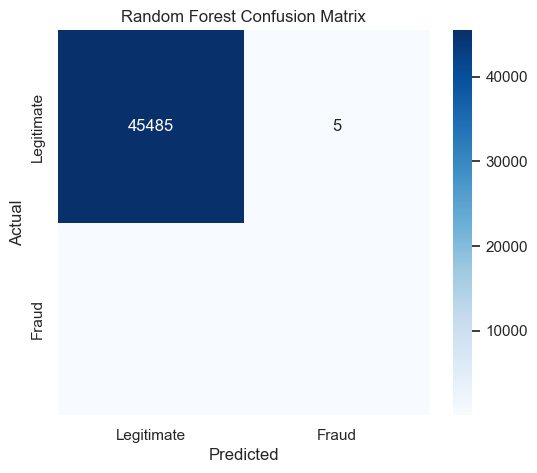

Gradient Boosting


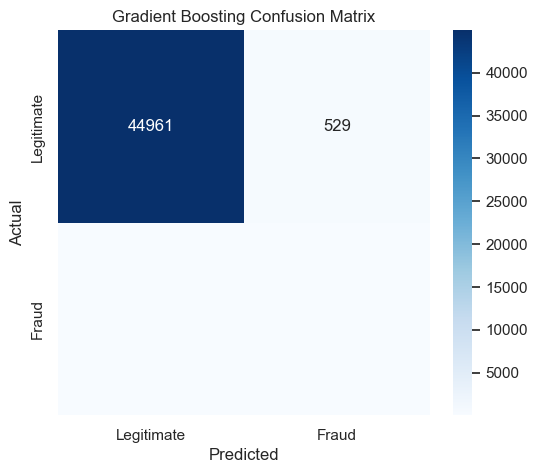

In [110]:
for name, model in models.items():

    print(name)

    plot_confusion_matrix(
        model,
        X_val,
        y_val,
        name
    )

In [111]:
from sklearn.metrics import classification_report

for name, model in models.items():

    print("\n", "=" * 50)

    print(name)

    print("=" * 50)

    predictions = model.predict(X_val)

    print(
        classification_report(
            y_val,
            predictions,
            target_names=[
                "Legitimate",
                "Fraud"
            ],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     45490
       Fraud       0.06      0.89      0.11        79

    accuracy                           0.98     45569
   macro avg       0.53      0.93      0.55     45569
weighted avg       1.00      0.98      0.99     45569


Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     45490
       Fraud       0.92      0.73      0.82        79

    accuracy                           1.00     45569
   macro avg       0.96      0.87      0.91     45569
weighted avg       1.00      1.00      1.00     45569


Gradient Boosting
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99     45490
       Fraud       0.11      0.85      0.20        79

    accuracy                           0.99     45569
   macro avg       0.56      0.92      0.60     45569
weighted avg       

In [112]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline as SklearnPipeline

from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [113]:
def get_models():

    return {
        "Logistic Regression": LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),

        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=20,
            random_state=42
        )
    }

In [114]:
def get_sampling_method(method):

    if method == "Class Weighting":
        return None

    elif method == "Undersampling":
        return RandomUnderSampler(
            sampling_strategy=0.1,
            random_state=42
        )

    elif method == "SMOTE":
        return SMOTE(
            sampling_strategy=0.1,
            random_state=42
        )

In [115]:
def evaluate_model(model, X_val, y_val):

    y_pred = model.predict(X_val)

    y_prob = model.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, y_prob),
        "PR-AUC": average_precision_score(y_val, y_prob),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp,
        "True Negatives": tn
    }

In [116]:
results = []

models = get_models()

imbalance_methods = [
    "Class Weighting",
    "Undersampling",
    "SMOTE"
]

for model_name, model in models.items():

    for method in imbalance_methods:

        print(f"Training {model_name} with {method}...")

        sampler = get_sampling_method(method)

        steps = [
            ("scaler", StandardScaler())
        ]

        if sampler is not None:
            steps.append(("sampler", sampler))

        steps.append(("classifier", model))

        pipeline = Pipeline(steps)

        if method == "Class Weighting" and model_name == "Gradient Boosting":

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )

            pipeline.fit(
                X_train,
                y_train,
                classifier__sample_weight=sample_weights
            )

        else:

            pipeline.fit(X_train, y_train)

        metrics = evaluate_model(
            pipeline,
            X_val,
            y_val
        )

        results.append({
            "Model": model_name,
            "Imbalance Method": method,
            **metrics
        })

results_df = pd.DataFrame(results)

print("ALL MODEL AND IMBALANCE METHOD RESULTS")
display(results_df.round(4))

Training Logistic Regression with Class Weighting...
Training Logistic Regression with Undersampling...
Training Logistic Regression with SMOTE...
Training Random Forest with Class Weighting...
Training Random Forest with Undersampling...
Training Random Forest with SMOTE...
Training Gradient Boosting with Class Weighting...
Training Gradient Boosting with Undersampling...
Training Gradient Boosting with SMOTE...
ALL MODEL AND IMBALANCE METHOD RESULTS


,Model,Imbalance Method,Precision,Recall,F1,ROC-AUC,PR-AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,Class Weighting,0.0599,0.8861,0.1123,0.9736,0.6790,1098,9,70,44392
1,Logistic Regression,Undersampling,0.0618,0.8861,0.1156,0.9717,0.6515,1062,9,70,44428
2,Logistic Regression,SMOTE,0.0551,0.8734,0.1036,0.9683,0.6817,1184,10,69,44306
3,Random Forest,Class Weighting,0.9206,0.7342,0.8169,0.9452,0.8136,5,21,58,45485
4,Random Forest,Undersampling,0.6809,0.8101,0.7399,0.9724,0.7031,30,15,64,45460
5,Random Forest,SMOTE,0.8732,0.7848,0.8267,0.9575,0.8070,9,17,62,45481
6,Gradient Boosting,Class Weighting,0.1124,0.8481,0.1985,0.9786,0.7244,529,12,67,44961
7,Gradient Boosting,Undersampling,0.3976,0.8354,0.5388,0.9764,0.7644,100,13,66,45390
8,Gradient Boosting,SMOTE,0.5856,0.8228,0.6842,0.9722,0.7156,46,14,65,45444



## Systematic Comparison of Models and Imbalance Techniques

A more systematic experiment is conducted to evaluate the performance of each classification model across three imbalance-handling approaches:

1. Class weighting
2. Random undersampling
3. SMOTE

This allows the effect of each imbalance-handling technique to be compared across different algorithms using the same training and validation datasets.


In [117]:
f1_comparison = results_df.pivot(
    index="Model",
    columns="Imbalance Method",
    values="F1"
)

display(f1_comparison.round(4))

Imbalance Method,Class Weighting,SMOTE,Undersampling
Model,,,
Gradient Boosting,0.1985,0.6842,0.5388
Logistic Regression,0.1123,0.1036,0.1156
Random Forest,0.8169,0.8267,0.7399


In [118]:
precision_comparison = results_df.pivot(
    index="Model",
    columns="Imbalance Method",
    values="Precision"
)

recall_comparison = results_df.pivot(
    index="Model",
    columns="Imbalance Method",
    values="Recall"
)

print("PRECISION COMPARISON")
display(precision_comparison.round(4))

print("RECALL COMPARISON")
display(recall_comparison.round(4))

PRECISION COMPARISON


Imbalance Method,Class Weighting,SMOTE,Undersampling
Model,,,
Gradient Boosting,0.1124,0.5856,0.3976
Logistic Regression,0.0599,0.0551,0.0618
Random Forest,0.9206,0.8732,0.6809


RECALL COMPARISON


Imbalance Method,Class Weighting,SMOTE,Undersampling
Model,,,
Gradient Boosting,0.8481,0.8228,0.8354
Logistic Regression,0.8861,0.8734,0.8861
Random Forest,0.7342,0.7848,0.8101


In [119]:
results = []
trained_models = {}

models = get_models()

imbalance_methods = [
    "Class Weighting",
    "Undersampling",
    "SMOTE"
]

for model_name, model in models.items():

    for method in imbalance_methods:

        print(f"Training {model_name} with {method}...")

        sampler = get_sampling_method(method)

        steps = [
            ("scaler", StandardScaler())
        ]

        if sampler is not None:
            steps.append(("sampler", sampler))

        steps.append(("classifier", model))

        pipeline = Pipeline(steps)

        if method == "Class Weighting" and model_name == "Gradient Boosting":

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_train
            )

            pipeline.fit(
                X_train,
                y_train,
                classifier__sample_weight=sample_weights
            )

        else:
            pipeline.fit(X_train, y_train)

        # Save the fitted model
        trained_models[(model_name, method)] = pipeline

        metrics = evaluate_model(
            pipeline,
            X_val,
            y_val
        )

        results.append({
            "Model": model_name,
            "Imbalance Method": method,
            **metrics
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

Training Logistic Regression with Class Weighting...
Training Logistic Regression with Undersampling...
Training Logistic Regression with SMOTE...
Training Random Forest with Class Weighting...
Training Random Forest with Undersampling...
Training Random Forest with SMOTE...
Training Gradient Boosting with Class Weighting...
Training Gradient Boosting with Undersampling...
Training Gradient Boosting with SMOTE...


,Model,Imbalance Method,Precision,Recall,F1,ROC-AUC,PR-AUC,False Positives,False Negatives,True Positives,True Negatives
0,Logistic Regression,Class Weighting,0.0599,0.8861,0.1123,0.9736,0.6790,1098,9,70,44392
1,Logistic Regression,Undersampling,0.0618,0.8861,0.1156,0.9717,0.6515,1062,9,70,44428
2,Logistic Regression,SMOTE,0.0551,0.8734,0.1036,0.9683,0.6817,1184,10,69,44306
3,Random Forest,Class Weighting,0.9206,0.7342,0.8169,0.9452,0.8136,5,21,58,45485
4,Random Forest,Undersampling,0.6809,0.8101,0.7399,0.9724,0.7031,30,15,64,45460
5,Random Forest,SMOTE,0.8732,0.7848,0.8267,0.9575,0.8070,9,17,62,45481
6,Gradient Boosting,Class Weighting,0.1124,0.8481,0.1985,0.9786,0.7244,529,12,67,44961
7,Gradient Boosting,Undersampling,0.3976,0.8354,0.5388,0.9764,0.7644,100,13,66,45390
8,Gradient Boosting,SMOTE,0.5856,0.8228,0.6842,0.9722,0.7156,46,14,65,45444


In [120]:
rf_smote_model = trained_models[
    ("Random Forest", "SMOTE")
]

rf_class_weight_model = trained_models[
    ("Random Forest", "Class Weighting")
]

In [121]:
from sklearn.metrics import precision_score, recall_score, f1_score

# The two leading candidates
candidates = {
    "Random Forest + SMOTE": rf_smote_model,
    "Random Forest + Class Weighting": rf_class_weight_model
}

threshold_results = []

for model_name, model in candidates.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in np.arange(0.10, 1.00, 0.01):

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "False Positives": fp,
            "False Negatives": fn,
            "True Positives": tp
        })

threshold_df = pd.DataFrame(threshold_results)

# Best F1 threshold for each model
best_thresholds = (
    threshold_df.sort_values("F1", ascending=False)
    .groupby("Model")
    .head(1)
    .sort_values("F1", ascending=False)
)

display(best_thresholds.round(4))

,Model,Threshold,Precision,Recall,F1,False Positives,False Negatives,True Positives
43,Random Forest + SMOTE,0.53,0.8857,0.7848,0.8322,8,17,62
132,Random Forest + Class Weighting,0.52,0.8857,0.7848,0.8322,8,17,62


In [122]:
# Retrieve the selected fitted model
final_model = rf_smote_model

# Predict probabilities on the test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_threshold = 0.53

test_predictions = (
    test_probabilities >= final_threshold
).astype(int)

# Evaluate the final model
print("FINAL RANDOM FOREST + SMOTE RESULTS")
print("=" * 50)

print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraud"]
))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)

print("Confusion Matrix:")
print(cm)

FINAL RANDOM FOREST + SMOTE RESULTS
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.85      0.84      0.85        98

    accuracy                           1.00     56962
   macro avg       0.93      0.92      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56850    14]
 [   16    82]]


In [123]:
print("ROC-AUC:", roc_auc_score(y_test, test_probabilities))

print("PR-AUC:", average_precision_score(y_test, test_probabilities))

ROC-AUC: 0.98563265521459
PR-AUC: 0.863342272614041


In [124]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    rf_smote_model,
    "../models/rf_smote_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [125]:
import json

threshold = 0.53

with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": threshold}, f, indent=4)

print("Threshold saved successfully!")

Threshold saved successfully!


In [126]:
print(os.listdir("../models"))

['rf_smote_model.pkl', 'threshold.json']


In [127]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nSaved model location:")
print(os.path.abspath("../models/rf_smote_model.pkl"))

Current working directory:
c:\Users\ThinkPad\Desktop\fraud-detection-system\notebooks

Saved model location:
c:\Users\ThinkPad\Desktop\fraud-detection-system\models\rf_smote_model.pkl


In [128]:
# Select one transaction labelled as fraud
fraud_sample = df[df["Class"] == 1].iloc[[0]]

# Extract the 30 model features, excluding the Class column
sample_features = fraud_sample.drop(columns=["Class"]).iloc[0].tolist()

# Display the transaction features
sample_features

[406.0,
 -2.3122265423263,
 1.95199201064158,
 -1.60985073229769,
 3.9979055875468,
 -0.522187864667764,
 -1.42654531920595,
 -2.53738730624579,
 1.39165724829804,
 -2.77008927719433,
 -2.77227214465915,
 3.20203320709635,
 -2.89990738849473,
 -0.595221881324605,
 -4.28925378244217,
 0.389724120274487,
 -1.14074717980657,
 -2.83005567450437,
 -0.0168224681808257,
 0.416955705037907,
 0.126910559061474,
 0.517232370861764,
 -0.0350493686052974,
 -0.465211076182388,
 0.320198198514526,
 0.0445191674731724,
 0.177839798284401,
 0.261145002567677,
 -0.143275874698919,
 0.0]

In [129]:
import json

request_data = {
    "features": sample_features
}

print(json.dumps(request_data, indent=2))

{
  "features": [
    406.0,
    -2.3122265423263,
    1.95199201064158,
    -1.60985073229769,
    3.9979055875468,
    -0.522187864667764,
    -1.42654531920595,
    -2.53738730624579,
    1.39165724829804,
    -2.77008927719433,
    -2.77227214465915,
    3.20203320709635,
    -2.89990738849473,
    -0.595221881324605,
    -4.28925378244217,
    0.389724120274487,
    -1.14074717980657,
    -2.83005567450437,
    -0.0168224681808257,
    0.416955705037907,
    0.126910559061474,
    0.517232370861764,
    -0.0350493686052974,
    -0.465211076182388,
    0.320198198514526,
    0.0445191674731724,
    0.177839798284401,
    0.261145002567677,
    -0.143275874698919,
    0.0
  ]
}


In [130]:
print(json.dumps(request_data))

{"features": [406.0, -2.3122265423263, 1.95199201064158, -1.60985073229769, 3.9979055875468, -0.522187864667764, -1.42654531920595, -2.53738730624579, 1.39165724829804, -2.77008927719433, -2.77227214465915, 3.20203320709635, -2.89990738849473, -0.595221881324605, -4.28925378244217, 0.389724120274487, -1.14074717980657, -2.83005567450437, -0.0168224681808257, 0.416955705037907, 0.126910559061474, 0.517232370861764, -0.0350493686052974, -0.465211076182388, 0.320198198514526, 0.0445191674731724, 0.177839798284401, 0.261145002567677, -0.143275874698919, 0.0]}
